<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~④ 는 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b>.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300"><br><br><small>④ 사이트로 돌아와 <b>『📓 내 Colab 실습 노트』</b> 칸에 붙여넣고 <b>『보관』</b>을 눌러요 — <b>『✅ 보관됨』</b>이 뜨면 선생님께 간 거예요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_paste.jpg" width="300">

<small>☁ <b>저장 확인</b> — 맨 위 노트 이름 옆에 <b>체크된 구름</b>이 보이면 내 드라이브에 <b>실시간으로 저장</b>되고 있어요. (구름이 없고 「Drive로 복사」가 보이면 아직 내 노트가 아니에요 — 파일 → Drive에 사본 저장)</small><br>

![체크된 구름 = 저장 잘 되는 중](https://raw.githubusercontent.com/SoojiNoh/baehwa-colab/main/nb/img/colab_saved.png)

# 📈 어제 기온으로 내일 예측 — 데이터 분석 실습

시간 순서로 분할해 지연 특성 회귀를 평가한다. 예상: 기온 변화가 작은 날에는 전날 기준선도 강하며 회귀가 항상 이기지는 않는다.

- **데이터 출처**: Kaggle · sumanthvrao/daily-climate-time-series-data — https://www.kaggle.com/datasets/sumanthvrao/daily-climate-time-series-data
- **라이선스**: CC0: Public Domain
- **이 카드의 질문**: 시간 순서로 분할해 지연 특성 회귀를 평가한다.

속성(열) 뜻은 수행평가 사이트 카드의 「속성(변수) 설명」 표를 보세요.

In [ ]:
# 0. 준비 — 그대로 실행해요 (한글 그래프 글꼴)
!pip -q install koreanize-matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib


## 1. 데이터 불러오기
CSV 파일을 표(DataFrame)로 읽어요. 함수 이름은 **읽다(read) + csv**.

📖 **오픈북** — 「#16 펭귄-분류」 숙제01 `pd.read_csv(url)`

In [ ]:
df = pd.______('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/DailyDelhiClimateTrain.csv')      # 힌트: CSV 를 읽는 함수
print(df.shape)
df.head()

## 2. 시작 코드 — 그대로 실행해 보기
카드의 시작 코드예요. 실행하고 결과를 아래 그림과 비교해요.

In [ ]:
import pandas as pd
df = pd.read_csv('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/DailyDelhiClimateTrain.csv')
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').set_index('date').asfreq('D')
df['전날기온'] = df['meantemp'].shift(1)
df['전날습도'] = df['humidity'].shift(1)
d = df[['meantemp','전날기온','전날습도']].dropna()
n = int(len(d)*0.8); a = d.iloc[:n]; b = d.iloc[n:]
m = LinearRegression().fit(a[['전날기온','전날습도']], a['meantemp'])
p = m.predict(b[['전날기온','전날습도']])
print('회귀 MAE', mean_absolute_error(b['meantemp'], p), 'R²', r2_score(b['meantemp'], p))
print('전날 기준 MAE', mean_absolute_error(b['meantemp'], b['전날기온']))

▶ 이렇게 나오면 맞아요 (무작위로 나누는 코드는 숫자가 조금 달라도 괜찮아요)

```
회귀 MAE 1.263708750718215 R² 0.912542435672359
전날 기준 MAE 1.2592436463168972
```


## 3-1. 전날 기온·습도를 입력으로 만든다.
직접 코드를 써 봐요. 막히면 위 시작 코드를 고쳐 써도 돼요.

In [ ]:
# 여기에 내 코드


## 3-2. 앞 80% 학습·뒤 20% 평가를 고정한다.
직접 코드를 써 봐요. 막히면 위 시작 코드를 고쳐 써도 돼요.

In [ ]:
# 여기에 내 코드


## 3-3. 선형회귀와 전날 기온 기준선의 MAE를 비교한다.
직접 코드를 써 봐요. 막히면 위 시작 코드를 고쳐 써도 돼요.

In [ ]:
# 여기에 내 코드


## 4. 내 생각 정리 (선택)
✍️ **(선택 — 필수 아니에요)** 답은 수행평가 사이트의 칸에 써요.

- 시간 순서로 분할해 지연 특성 회귀를 평가한다.
- 앞 80% 학습·뒤 20% 평가를 고정한다.
- 선형회귀와 전날 기온 기준선의 MAE를 비교한다.
- 그래프에서 읽은 것 → 사이트 「1-2. 분석 방법과 그래프 설명」
- 이 결과를 그대로 믿기 어려운 이유 → 「1-3. 한계」
- 내 코드에서 중요한 3줄과 이유 → 「1-1. 이 코드 3줄은 왜 썼나」

## 🤖 머신러닝으로 예측·분류하기
회귀 — 숫자를 맞혀요. 평균 오차(MAE)와 설명력(R²)을 봐요.

- 학습용 70%로 배우고, 시험용 30%로 채점해요(`train_test_split`).
- 결과 숫자는 아래에 저장돼 있어요. 직접 실행해서 같은 숫자가 나오는지 확인해요.
- 보고서: 중요한 코드 3줄 → 「1-1」, 숫자가 뜻하는 것 → 「1-2」, 숫자가 낮은 이유 → 「1-3 한계」

평균 오차(MAE) 1.35
설명력(R²) 0.938


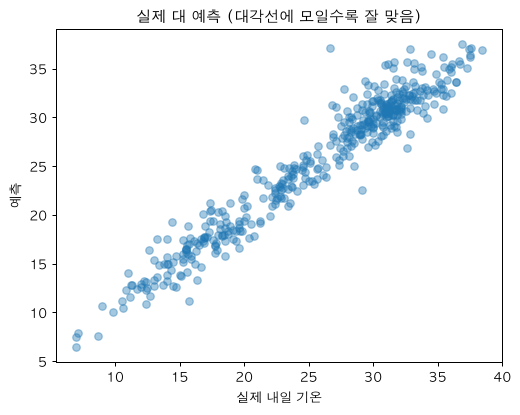

In [1]:
# 🤖 머신러닝 단계 — 그대로 실행해요
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split   # 학습용·시험용 나누기
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
df = pd.read_csv('https://baehwa-ai-2026.web.app/dataproject/csv/kaggle/DailyDelhiClimateTrain.csv')
df['오늘 기온'] = df['meantemp']
df['내일 기온'] = df['meantemp'].shift(-1)   # 다음 날 기온을 정답으로
df = df.dropna()
X = df[['오늘 기온', 'humidity', 'wind_speed']]                     # 넣을 열(특징)
y = df['내일 기온']                     # 맞힐 정답(숫자)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)   # 70% 학습 · 30% 시험
model = LinearRegression()   # 선형 회귀: 직선(평면)으로 맞추기
model.fit(X_train, y_train)          # 학습
pred = model.predict(X_test)         # 시험용으로 예측
print('평균 오차(MAE)', round(mean_absolute_error(y_test, pred), 2))   # 평균적으로 얼마나 틀렸나
print('설명력(R²)', round(r2_score(y_test, pred), 3))                  # 1에 가까울수록 잘 맞음
plt.scatter(y_test, pred, alpha=0.4); plt.xlabel('실제 ' + '내일 기온'); plt.ylabel('예측')
plt.title('실제 대 예측 (대각선에 모일수록 잘 맞음)'); plt.show()